# Лабораторная работа №2

## Нейросетевой перевод на базе Hugging Face Transformers (MarianMT, NLLB)

**ФИО студента:** Егоров Виталий Дмитриевич
**Группа:** ИНФА-221
**Вариант:** 2 (Кибербезопасность и защита информации)

---

**Цель:** развернуть NMT-пайплайн, исследовать субсловную токенизацию, батчинг, условную
кросс-энтропию и cross-attention, сравнить специализированную EN→RU модель **MarianMT**
с многоязычной **NLLB**.

**Максимум: 20 баллов**

| Критерий | Состав | Баллы |
|---|---|---:|
| Работоспособность пайплайна | MarianMT — 2 · NLLB — 2 · batching/loss/attention — 2 | **6** |
| Корректность лингвистической обработки | языковые коды и токенизация — 2 · объём корпуса (120+ сегментов, 100+ терминов) — 1 · glossary QA — 2 | **5** |
| Анализ ошибок и аргументация | 5+ различий — 2 · интерпретация loss/attention — 2 · вывод — 1 | **5** |
| Оформление и воспроизводимость | результаты и графики — 1 · README — 1 · зависимости — 1 · структура — 1 | **4** |

---

### Порядок выполнения

1. **Runtime → Change runtime type → T4 GPU.** Без GPU перевод 120 сегментов двумя моделями
   займёт часы.
2. Выполните блоки 0–1 (установка, окружение).
3. Блок 2 — подключите **свои** файлы из ЛР № 1 (`segments_en.csv`, `glossary.csv`,
   `aligned_reference.csv`) и убедитесь, что проверка объёма даёт «ГОТОВО».
4. Реализуйте функции в блоках 3–8 вместо маркеров `# TODO`.
5. Запустите блок 9 — все автотесты должны пройти без `AssertionError`.
6. Выполните блоки 10–15: перевод корпуса, QA, сравнение, **графики**, отчёт.
7. Заполните вручную колонки `preferred` и `comment` — автоматический выбор модели их не
   заменяет.

### Обязательный минимум

| Требование | Значение |
|---|---|
| Сегментов в корпусе, переведённых **каждой** моделью | **120+** |
| Терминов в глоссарии, разобранных токенизаторами | **100+** |
| Пар `source` / `reference` для кросс-энтропии | 5+ |
| Пар для анализа cross-attention | 2+ |
| Режимы инференса | последовательный и пакетный |
| Содержательных различий с аргументацией | 5+ |
| Графиков в отчёте | 4+ |

> Если в ЛР № 1 корпус меньше, расширьте исходный учебный модуль и глоссарий до требуемого
> объёма **до** начала работы: все дальнейшие выводы опираются на статистику, а на 15
> сегментах она недостоверна.

### Две особенности актуальных версий библиотек

* **`attn_implementation="eager"`.** В `transformers` 5.x модели по умолчанию используют
  ускоренное внимание (SDPA/Flash), которое не сохраняет веса: `outputs.cross_attentions`
  окажется пустым, и блок 7 упадёт с `IndexError: tuple index out of range`.
* **Предупреждение `max_new_tokens` / `max_length`.** Безобидно (приоритет у
  `max_new_tokens`), но зашумляет вывод — логирование понижается в блоке 1.

## Блок 0. Установка зависимостей

`torch` в Colab предустановлен. Ставим `transformers`, `sentencepiece` (нужен токенизатору
NLLB) и `sacremoses` (предобработка MarianMT).

In [1]:
!pip install -q "transformers>=4.40" sentencepiece sacremoses

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 867.8/867.8 kB 15.0 MB/s eta 0:00:00


## Блок 1. Окружение и структура каталогов

Ячейка готова — менять её не нужно. Зафиксированное зерно и вывод версий обязательны для
воспроизводимости (критерий 4).

In [2]:
from __future__ import annotations

import json
import platform
import random
import time
from pathlib import Path
from typing import Any, Dict, Iterable, List, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

transformers.logging.set_verbosity_error()   # убирает предупреждение о max_length

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

BASE = Path("/content/lab02") if Path("/content").exists() else Path.cwd() / "lab02"
DATA = BASE / "data"
RESULTS = BASE / "results"
FIGURES = BASE / "figures"
for folder in (DATA, RESULTS, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MARIAN_NAME = "Helsinki-NLP/opus-mt-en-ru"
NLLB_NAME = "facebook/nllb-200-distilled-600M"
SRC_LANG, TGT_LANG = "eng_Latn", "rus_Cyrl"

MIN_SEGMENTS, MIN_TERMS = 120, 100

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

ENVIRONMENT = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "-",
}
for key, value in ENVIRONMENT.items():
    print(f"{key:>13}: {value}")
print(f"{'base_dir':>13}: {BASE}")
if DEVICE.type != "cuda":
    print("\nВНИМАНИЕ: GPU не подключён. Runtime -> Change runtime type -> T4 GPU.")

       python: 3.13.15
        torch: 2.11.0+cu130
 transformers: 5.18.0
       device: cuda
          gpu: Tesla T4
     base_dir: /content/lab02


## Блок 2. Данные своего варианта из ЛР № 1

Нужны три файла:

| Файл | Обязательные колонки | Объём |
|---|---|---|
| `data/segments_en.csv` | `segment_id`, `source` | не менее 120 сегментов |
| `data/glossary.csv` | `en`, `ru` | не менее 100 терминов |
| `data/aligned_reference.csv` | `segment_id`, `source`, `reference` | те же сегменты |

Извлекаем файлы tbx и tmx.

In [9]:
import xml.etree.ElementTree as ET
import pandas as pd

VARIANT = 2
tbx_file = DATA / f"variant_{VARIANT}.tbx"
tmx_file = DATA / f"variant_{VARIANT}.tmx"

# Проверяем, есть ли файлы в папке DATA
if tbx_file.exists() and tmx_file.exists():
    print("Найдены ваши файлы TBX/TMX. Извлекаем из них данные...")

    # 1. Извлекаем глоссарий из TBX
    glossary_data = []
    tree = ET.parse(tbx_file)
    for termEntry in tree.getroot().findall('.//termEntry'):
        en_term, ru_term = "", ""
        for langSet in termEntry.findall('langSet'):
            lang = langSet.get('{http://www.w3.org/XML/1998/namespace}lang')
            term_elem = langSet.find('.//term')
            if term_elem is not None:
                if lang == 'en': en_term = term_elem.text
                elif lang == 'ru': ru_term = term_elem.text
        if en_term and ru_term:
            glossary_data.append({"en": en_term, "ru": ru_term})
    pd.DataFrame(glossary_data).to_csv(DATA / "glossary.csv", index=False, encoding="utf-8")

    # 2. Извлекаем сегменты из TMX
    segments_data, reference_data = [], []
    tree = ET.parse(tmx_file)
    for i, tu in enumerate(tree.getroot().findall('.//tu'), 1):
        en_seg, ru_seg = "", ""
        for tuv in tu.findall('tuv'):
            lang = tuv.get('{http://www.w3.org/XML/1998/namespace}lang')
            seg_elem = tuv.find('seg')
            if seg_elem is not None:
                if lang == 'en': en_seg = seg_elem.text
                elif lang == 'ru': ru_seg = seg_elem.text
        if en_seg and ru_seg:
            seg_id = f"s{i:03d}"
            segments_data.append({"segment_id": seg_id, "source": en_seg})
            reference_data.append({"segment_id": seg_id, "source": en_seg, "reference": ru_seg})

    pd.DataFrame(segments_data).to_csv(DATA / "segments_en.csv", index=False, encoding="utf-8")
    pd.DataFrame(reference_data).to_csv(DATA / "aligned_reference.csv", index=False, encoding="utf-8")
    print("Файлы CSV успешно созданы из TBX/TMX!\n")

else:
    # --- ЕСЛИ ФАЙЛОВ НЕТ, РАБОТАЕТ СТАРЫЙ КОД УЧИТЕЛЯ (Способ 1) -----------
    try:
        from google.colab import files
        print("Выберите segments_en.csv, glossary.csv, aligned_reference.csv (или закройте диалог, чтобы использовать демо-данные)")
        uploaded = files.upload()
        for name, content in uploaded.items():
            (DATA / name).write_bytes(content)
    except Exception as error:
        print("Загрузка пропущена:", error.__class__.__name__)


# --- ДЕМО-НАБОР (Оригинал учителя) -----------------------------------------
DEMO_PARALLEL = [
    ("A variable stores a value.", "Переменная хранит значение."),
    ("A condition controls which branch is executed.", "Условие определяет, какая ветвь выполняется."),
    ("A loop repeats a block of instructions.", "Цикл повторяет блок инструкций."),
    ("A function can return a value.", "Функция может возвращать значение."),
]
DEMO_GLOSSARY = [("variable", "переменная"), ("value", "значение"), ("loop", "цикл"), ("function", "функция")]

if not (DATA / "segments_en.csv").exists():
    print("\nФайлы ЛР № 1 не найдены — создаётся демонстрационный набор.")
    pd.DataFrame([{"segment_id": f"s{i:03d}", "source": src} for i, (src, _) in enumerate(DEMO_PARALLEL, 1)]).to_csv(DATA / "segments_en.csv", index=False, encoding="utf-8")
    pd.DataFrame([{"segment_id": f"s{i:03d}", "source": src, "reference": ref} for i, (src, ref) in enumerate(DEMO_PARALLEL, 1)]).to_csv(DATA / "aligned_reference.csv", index=False, encoding="utf-8")
    pd.DataFrame(DEMO_GLOSSARY, columns=["en", "ru"]).to_csv(DATA / "glossary.csv", index=False, encoding="utf-8")


# --- ПРОВЕРКА (Оригинал учителя) -------------------------------------------
segments_df = pd.read_csv(DATA / "segments_en.csv")
glossary_df = pd.read_csv(DATA / "glossary.csv")
aligned_df = pd.read_csv(DATA / "aligned_reference.csv")

assert {"segment_id", "source"} <= set(segments_df.columns), "segments_en.csv: не те колонки"
assert {"en", "ru"} <= set(glossary_df.columns), "glossary.csv: нужны колонки en и ru"
assert {"segment_id", "source", "reference"} <= set(aligned_df.columns), "aligned_reference.csv: нужны колонки segment_id, source, reference"
assert len(segments_df) == len(aligned_df), "segments_en.csv и aligned_reference.csv должны содержать одинаковые сегменты"

def dataset_ready(segments: pd.DataFrame, glossary: pd.DataFrame) -> bool:
    checks = [("сегментов", len(segments), MIN_SEGMENTS), ("терминов", len(glossary), MIN_TERMS)]
    ready = True
    for label, actual, required in checks:
        status = "ГОТОВО" if actual >= required else "НЕДОСТАТОЧНО"
        ready &= actual >= required
        print(f"  {label:<10} {actual:>4} / {required:<4} {status}")
    return ready

# Если в DATA находятся собственные артефакты ЛР № 1, используются именно они
existing = sorted(list(DATA.glob("*.tmx")) + list(DATA.glob("*.tbx")))
if existing:
    print("В каталоге DATA уже есть артефакты ЛР № 1 — используются они:")
    for path in existing:
        print(f"  {path.name:<22} {path.stat().st_size:>7} байт")

print(f"\nПроверка объёма корпуса:")
READY = dataset_ready(segments_df, glossary_df)
print("\nСтатус:", "корпус соответствует требованиям" if READY else "работа на этих данных к сдаче НЕ принимается")
print(f"Средняя длина сегмента: {segments_df['source'].str.split().str.len().mean():.1f} слов")
segments_df.head()

Найдены ваши файлы TBX/TMX. Извлекаем из них данные...
Файлы CSV успешно созданы из TBX/TMX!

В каталоге DATA уже есть артефакты ЛР № 1 — используются они:
  variant_2.tbx            74393 байт
  variant_2.tmx            59003 байт

Проверка объёма корпуса:
  сегментов   120 / 120  ГОТОВО
  терминов    100 / 100  ГОТОВО

Статус: корпус соответствует требованиям
Средняя длина сегмента: 12.3 слов


,segment_id,source
0,s001,Access control ensures that access to assets i...
1,s002,"An attack is an attempt to destroy, expose, al..."
2,s003,The audit is a systematic and documented proce...
3,s004,The audit scope defines the extent and boundar...
4,s005,Authentication provides assurance that a claim...


## Блок 3. Загрузка моделей (шаги 1–2, 8)

**Подсказки.** `AutoTokenizer.from_pretrained` / `AutoModelForSeq2SeqLM.from_pretrained`;
модель переносится на устройство методом `.to(device)` и переводится в режим инференса
`.eval()` — без этого включён dropout и результат нестабилен. Для NLLB токенизатору
передаются `src_lang` и `tgt_lang`.

**Обязательно:** передайте `attn_implementation="eager"` в `from_pretrained`, иначе блок 7
не получит веса внимания. Старые версии `transformers` этого аргумента не знают — оберните
вызов в `try / except (TypeError, ValueError)`.

In [10]:
def load_seq2seq(model_name: str, device: torch.device,
                 eager_attention: bool = True,
                 **tokenizer_kwargs: Any) -> Tuple[Any, Any]:
    """Загрузить токенизатор и модель seq2seq и подготовить её к инференсу.
    ...
    """
    tokenizer = AutoTokenizer.from_pretrained(model_name, **tokenizer_kwargs)
    try:
        model = AutoModelForSeq2SeqLM.from_pretrained(
            model_name,
            **( {"attn_implementation": "eager"} if eager_attention else {} ),
        )
    except (TypeError, ValueError):
        model = AutoModelForSeq2SeqLM.from_pretrained(model_name)
    model = model.to(device)
    model.eval()
    return tokenizer, model

## Блок 4. Перевод сегментов (шаги 4–5, 9)

**Подсказки.** Токенизация пакета: `tokenizer(list_of_texts, return_tensors="pt",
padding=True, truncation=True).to(device)`. Генерация — под `torch.no_grad()`, декодирование —
`tokenizer.batch_decode(..., skip_special_tokens=True)`.

Для NLLB направление перевода задаётся аргументом `forced_bos_token_id`, который получают как
`tokenizer.convert_tokens_to_ids("rus_Cyrl")`. Без него язык результата не гарантирован.

In [11]:
def translate_batch(texts: Sequence[str], tokenizer: Any, model: Any,
                    device: torch.device, num_beams: int = 4,
                    max_new_tokens: int = 128,
                    forced_bos_token_id: Optional[int] = None) -> List[str]:
    """Перевести список сегментов одним пакетом."""
    batch = tokenizer(list(texts), return_tensors="pt",
                      padding=True, truncation=True).to(device)
    generate_kwargs: Dict[str, Any] = {
        "num_beams": num_beams,
        "max_new_tokens": max_new_tokens,
    }
    if forced_bos_token_id is not None:
        generate_kwargs["forced_bos_token_id"] = forced_bos_token_id

    with torch.no_grad():
        generated = model.generate(**batch, **generate_kwargs)
    return tokenizer.batch_decode(generated, skip_special_tokens=True)


def timed_sequential(texts: Sequence[str], tokenizer: Any, model: Any,
                     device: torch.device, **kwargs: Any) -> Tuple[List[str], float]:
    """Перевести сегменты по одному и вернуть (переводы, время в секундах)."""
    start_time = time.perf_counter()
    outputs = [translate_batch([text], tokenizer, model, device, **kwargs)[0]
               for text in texts]
    return outputs, time.perf_counter() - start_time


def timed_batched(texts: Sequence[str], tokenizer: Any, model: Any,
                  device: torch.device, batch_size: int = 8,
                  **kwargs: Any) -> Tuple[List[str], float]:
    """Перевести сегменты пачками по batch_size и вернуть (переводы, время)."""
    start_time = time.perf_counter()
    outputs: List[str] = []
    for offset in range(0, len(texts), batch_size):
        outputs.extend(translate_batch(texts[offset:offset + batch_size],
                                       tokenizer, model, device, **kwargs))
    return outputs, time.perf_counter() - start_time

## Блок 5. Субсловная токенизация (шаги 3, 10)

**Подсказка.** `tokenizer(term, add_special_tokens=False)["input_ids"]`, затем
`tokenizer.convert_ids_to_tokens(ids)`. Специальные токены отключаются намеренно: иначе в
разборе появятся `</s>` и код языка.

In [12]:
def tokenize_terms(terms: Sequence[str], tokenizer: Any, label: str) -> pd.DataFrame:
    """Разобрать термины токенизатором модели."""
    rows: List[Dict[str, Any]] = []
    for term in terms:
        ids = tokenizer(term, add_special_tokens=False)["input_ids"]
        tokens = tokenizer.convert_ids_to_tokens(ids)
        rows.append({
            "model": label,
            "term": term,
            "n_words": len(term.split()),
            "n_tokens": len(tokens),
            "tokens": " ".join(tokens),
            "is_word_level": len(tokens) == len(term.split()),
        })
    return pd.DataFrame(rows)

## Блок 6. Условная кросс-энтропия (шаг 6)

$$\mathcal{L} = -\frac{1}{T}\sum_{t=1}^{T}\log P\left(y_t \mid y_{1:t-1}, x\right)$$

**Подсказка.** Эталон передаётся в токенизатор аргументом `text_target=...`; при прямом вызове
модели `model(**batch)` поле `outputs.loss` уже содержит усреднённую кросс-энтропию.

In [13]:
def sequence_cross_entropy(source: str, target: str, tokenizer: Any,
                           model: Any, device: torch.device) -> float:
    """Вычислить условную кросс-энтропию целевой строки при данном источнике."""
    batch = tokenizer(source, text_target=target, return_tensors="pt",
                      truncation=True).to(device)
    with torch.no_grad():
        outputs = model(**batch)
    return float(outputs.loss)

## Блок 7. Cross-attention (шаг 7)

**Подсказки.** Вызов модели с `output_attentions=True, return_dict=True`;
`outputs.cross_attentions` — кортеж по слоям, каждый элемент имеет форму
`[batch, heads, target_len, source_len]`. Головы усредняются: `attn[0].mean(dim=0)`.
В `batch["labels"]` могут быть значения `-100` (игнорируемые позиции) — их надо отфильтровать
перед `convert_ids_to_tokens`.

**Обязательно:** если `outputs.cross_attentions` пуст, поднимите `RuntimeError` с понятным
текстом. Пустой кортеж означает, что модель загружена без `attn_implementation="eager"`.

In [14]:
def extract_cross_attention(source: str, target: str, tokenizer: Any, model: Any,
                            device: torch.device, layer: int = -1
                            ) -> Tuple[pd.DataFrame, Tuple[int, ...]]:
    """Извлечь усреднённую по головам матрицу cross-attention."""
    batch = tokenizer(source, text_target=target, return_tensors="pt",
                      truncation=True).to(device)
    with torch.no_grad():
        outputs = model(**batch, output_attentions=True, return_dict=True)

    attentions = getattr(outputs, "cross_attentions", None)
    if not attentions:
        raise RuntimeError(
            "Модель не вернула cross_attentions. Загрузите её с "
            'attn_implementation="eager": ускоренные реализации внимания '
            "(SDPA/Flash) веса не сохраняют.")

    layer_attention = attentions[layer]
    shape = tuple(layer_attention.shape)
    matrix = layer_attention[0].mean(dim=0).float().cpu().numpy()

    src_tokens = tokenizer.convert_ids_to_tokens(batch["input_ids"][0].cpu().tolist())
    labels = [token_id for token_id in batch["labels"][0].cpu().tolist() if token_id != -100]
    tgt_tokens = tokenizer.convert_ids_to_tokens(labels)

    matrix = matrix[:len(tgt_tokens), :len(src_tokens)]
    frame = pd.DataFrame(matrix, index=tgt_tokens[:matrix.shape[0]],
                         columns=src_tokens[:matrix.shape[1]])
    return frame, shape

## Блок 8. Терминологический QA и сводная таблица (шаги 12–13)

**Подсказки.** Проверка идёт по глоссарию ЛР № 1. Из-за русской морфологии точное вхождение
даёт ложные срабатывания («сложность» → «сложности»), поэтому сравнивайте нормализованные
формы: достаточно грубого отсечения окончаний. Каждое найденное нарушение затем
подтверждается вручную.

In [15]:
RU_ENDINGS = ("иями", "ями", "ами", "ого", "ому", "ыми", "ей", "ой", "ом", "ах",
              "ям", "ов", "ые", "ый", "ая", "ое", "ий", "ь", "и", "ы", "а", "е", "о",
              "у", "ю", "я")

def ru_stem(word: str) -> str:
    """Грубая нормализация русского слова: отсечение частотных окончаний."""
    word = word.lower().replace("ё", "е").strip(".,;:()«»\"'")
    for ending in RU_ENDINGS:
        if len(word) - len(ending) >= 4 and word.endswith(ending):
            return word[: -len(ending)]
    return word

def term_present(term_ru: str, text: str) -> bool:
    """Проверить наличие русского термина в тексте с учётом словоизменения."""
    text_stems = [ru_stem(token) for token in text.lower().split()]
    return all(ru_stem(part) in text_stems for part in term_ru.split())

def term_compliance(source: str, translation: str,
                    glossary: pd.DataFrame) -> List[Dict[str, str]]:
    """Найти термины глоссария, присутствующие в источнике, но отсутствующие в переводе."""
    violations: List[Dict[str, str]] = []
    source_lower = source.lower()
    for row in glossary.itertuples(index=False):
        term_en, term_ru = str(row.en).lower(), str(row.ru)
        if term_en in source_lower and not term_present(term_ru, translation):
            violations.append({"source_term": str(row.en), "preferred_ru": term_ru})
    return violations


def write_jsonl(records: Iterable[Dict[str, Any]], path: Path) -> Path:
    """Записать записи в JSON Lines: один объект на строку, UTF-8, ensure_ascii=False."""
    with open(path, "w", encoding="utf-8") as handler:
        for record in records:
            handler.write(json.dumps(record, ensure_ascii=False) + "\n")
    return path


def build_comparison_table(marian_records: Sequence[Dict[str, Any]],
                           nllb_records: Sequence[Dict[str, Any]],
                           references: Sequence[str]) -> pd.DataFrame:
    """Собрать сводную таблицу сравнения двух моделей."""
    frame = pd.DataFrame({
        "segment_id": [record["id"] for record in marian_records],
        "source": [record["source"] for record in marian_records],
        "marian": [record["translation"] for record in marian_records],
        "nllb": [record["translation"] for record in nllb_records],
        "reference": list(references),
    })
    frame["identical"] = frame["marian"] == frame["nllb"]
    frame["preferred"] = ""   # Заполняется вручную
    frame["comment"] = ""     # Заполняется вручную
    return frame

## Блок 9. Автотесты

Запускайте по порядку **после** реализации функций. Тест 1 работает без моделей; тесты 2–6
скачивают веса (первый запуск — несколько минут).

In [16]:
# --- Тест 1: функции, не требующие моделей -------------------------------
demo_glossary = pd.DataFrame([("loop", "цикл"), ("function", "функция")],
                             columns=["en", "ru"])

assert term_compliance("A loop repeats instructions.", "Цикл повторяет инструкции.",
                       demo_glossary) == [], "Термин передан — нарушений быть не должно"

violations = term_compliance("A loop repeats instructions.",
                             "Итерация повторяет инструкции.", demo_glossary)
assert len(violations) == 1, f"Ожидается 1 нарушение, получено {len(violations)}"
assert violations[0]["source_term"] == "loop", "Не то поле source_term"
assert violations[0]["preferred_ru"] == "цикл", "Не то поле preferred_ru"

assert term_compliance("A function returns a value.", "Функции возвращают значение.",
                       demo_glossary) == [], \
    "Словоизменение («функции») не должно считаться нарушением"

assert term_compliance("Nothing relevant here.", "Ничего существенного.",
                       demo_glossary) == [], "Термина нет в источнике — проверять нечего"

path = write_jsonl([{"id": "s001", "source": "A", "translation": "Б", "model": "m"}],
                   RESULTS / "_selftest.jsonl")
lines = Path(path).read_text(encoding="utf-8").strip().split("\n")
assert len(lines) == 1, "JSONL: одна запись — одна строка"
assert json.loads(lines[0])["translation"] == "Б", "JSONL: кириллица должна сохраняться как есть"
Path(path).unlink()

table = build_comparison_table(
    [{"id": "s001", "source": "A loop.", "translation": "Цикл."}],
    [{"id": "s001", "source": "A loop.", "translation": "Цикл."}],
    ["Цикл."])
for column in ["segment_id", "source", "marian", "nllb", "reference",
               "identical", "preferred", "comment"]:
    assert column in table.columns, f"В сводной таблице нет колонки '{column}'"
assert bool(table.loc[0, "identical"]), "Одинаковые переводы -> identical = True"
assert table.loc[0, "preferred"] == "", "Колонка preferred заполняется вручную, а не кодом"
print("Тест 1 (функции без моделей) — OK")

Тест 1 (функции без моделей) — OK


In [17]:
# --- Тест 2: MarianMT ----------------------------------------------------
marian_tokenizer, marian_model = load_seq2seq(MARIAN_NAME, DEVICE)

assert marian_model.training is False, "Модель должна быть переведена в режим eval()"
assert str(next(marian_model.parameters()).device).startswith(DEVICE.type), \
    "Модель не перенесена на выбранное устройство"
assert getattr(marian_model.config, "_attn_implementation", "eager") == "eager", \
    "Модель загружена не в режиме eager — блок 7 не получит веса внимания"

outputs = translate_batch(["A loop repeats a block of instructions.",
                           "A function can return a value."],
                          marian_tokenizer, marian_model, DEVICE)
assert len(outputs) == 2, "Число переводов должно совпадать с числом входных сегментов"
assert all(text.strip() for text in outputs), "Пустой перевод"
assert any("а" <= char <= "я" for char in outputs[0].lower()), \
    "Ожидается перевод на русский язык"
print("Тест 2 (MarianMT) — OK")
for text in outputs:
    print(" ", text)

config.json:   0%|          | 0.00/1.38k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/803k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.60M [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  307MB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Тест 2 (MarianMT) — OK
  Цепь повторяет блок инструкций.
  Функция может вернуть значение.


In [18]:
# --- Тест 3: токенизация -------------------------------------------------
tokens_df = tokenize_terms(glossary_df["en"].tolist(), marian_tokenizer, "MarianMT")

assert isinstance(tokens_df, pd.DataFrame), "tokenize_terms должна вернуть DataFrame"
assert len(tokens_df) == len(glossary_df), "Разобраны не все термины"
for column in ["model", "term", "n_words", "n_tokens", "tokens", "is_word_level"]:
    assert column in tokens_df.columns, f"Нет колонки '{column}'"
assert (tokens_df["n_tokens"] >= 1).all(), "Число токенов не может быть нулевым"
assert tokens_df["tokens"].str.strip().ne("").all(), "Пустая строка токенов"
assert not tokens_df["tokens"].str.contains("</s>").any(), \
    "Спецтокены должны быть отключены (add_special_tokens=False)"
print("Тест 3 (токенизация) — OK")
tokens_df.head()

Тест 3 (токенизация) — OK


,model,term,n_words,n_tokens,tokens,is_word_level
0,MarianMT,access control,2,2,▁access ▁control,True
1,MarianMT,attack,1,1,▁attack,True
2,MarianMT,audit,1,1,▁audit,True
3,MarianMT,audit scope,2,2,▁audit ▁scope,True
4,MarianMT,authentication,1,1,▁authentication,True


In [19]:
# --- Тест 4: кросс-энтропия ----------------------------------------------
source_demo = aligned_df.loc[0, "source"]
reference_demo = aligned_df.loc[0, "reference"]

loss_value = sequence_cross_entropy(source_demo, reference_demo,
                                    marian_tokenizer, marian_model, DEVICE)
assert isinstance(loss_value, float), "Функция должна возвращать float, а не тензор"
assert loss_value > 0, "Кросс-энтропия положительна"
assert np.isfinite(loss_value), "Получено inf/nan — проверьте передачу text_target"

loss_wrong = sequence_cross_entropy(source_demo, "Совершенно посторонний текст про погоду.",
                                    marian_tokenizer, marian_model, DEVICE)
assert loss_wrong > loss_value, \
    "Нерелевантная строка должна получать больший loss, чем эталон"
print(f"Тест 4 (кросс-энтропия) — OK: эталон {loss_value:.4f}, шум {loss_wrong:.4f}")

Тест 4 (кросс-энтропия) — OK: эталон 1.5184, шум 6.3486


In [20]:
# --- Тест 5: cross-attention ---------------------------------------------
frame, shape = extract_cross_attention(source_demo, reference_demo,
                                       marian_tokenizer, marian_model, DEVICE)

assert isinstance(frame, pd.DataFrame), "Первым элементом возвращается DataFrame"
assert len(shape) == 4, "Форма тензора: (batch, heads, target_len, source_len)"
assert shape[0] == 1, "Ожидается batch = 1"
assert frame.shape[0] == len(frame.index), "Строки — целевые токены"
assert frame.shape[1] == len(frame.columns), "Колонки — исходные токены"
assert frame.shape[1] <= shape[3] and frame.shape[0] <= shape[2], \
    "Размер матрицы не должен превышать форму тензора"
assert float(frame.values.min()) >= 0.0, "Веса внимания неотрицательны"
print(f"Тест 5 (cross-attention) — OK: shape={shape}, матрица {frame.shape}")
frame.iloc[:5, :6].round(3)

Тест 5 (cross-attention) — OK: shape=(1, 8, 16, 13), матрица (16, 13)


,▁Access,▁control,▁ensures,▁that,▁access,▁to
▁Управление,0.166,0.436,0.063,0.015,0.013,0.003
▁доступом,0.433,0.140,0.057,0.006,0.029,0.011
▁гарантирует,0.032,0.036,0.494,0.038,0.019,0.004
",",0.015,0.009,0.018,0.043,0.112,0.017
▁что,0.007,0.005,0.019,0.140,0.045,0.006


In [21]:
# --- Тест 6: NLLB и языковые коды ----------------------------------------
nllb_tokenizer, nllb_model = load_seq2seq(NLLB_NAME, DEVICE,
                                          src_lang=SRC_LANG, tgt_lang=TGT_LANG)
RUS_ID = nllb_tokenizer.convert_tokens_to_ids(TGT_LANG)

assert isinstance(RUS_ID, int) and RUS_ID > 0, \
    f"Код языка '{TGT_LANG}' не найден — проверьте написание"

nllb_output = translate_batch(["A loop repeats a block of instructions."],
                              nllb_tokenizer, nllb_model, DEVICE,
                              forced_bos_token_id=RUS_ID)[0]
assert nllb_output.strip(), "Пустой перевод NLLB"
assert any("а" <= char <= "я" for char in nllb_output.lower()), \
    "forced_bos_token_id не задан — язык результата не гарантирован"
print("Тест 6 (NLLB) — OK")
print(" ", nllb_output)

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

...

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.46GB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

Тест 6 (NLLB) — OK
  Цепочка повторяет блок инструкций.


## Блок 10. Батчинг и время инференса (шаг 5)

Замерьте оба режима на всех своих сегментах и сохраните `results/timing.csv`. Первый вызов не
включайте в замер: он содержит инициализацию вычислителя. Полезно сравнить несколько размеров
пачки (4, 8, 16) — выигрыш насыщается.

In [22]:
sources = segments_df["source"].tolist()

_ = translate_batch(sources[:2], marian_tokenizer, marian_model, DEVICE)  # прогрев

seq_out, seq_time = timed_sequential(sources, marian_tokenizer, marian_model, DEVICE)

timing_rows: List[Dict[str, Any]] = [
    {"model": MARIAN_NAME, "mode": "sequential", "batch_size": 1,
     "n_segments": len(sources), "total_s": round(seq_time, 3),
     "per_segment_s": round(seq_time / len(sources), 3), "device": str(DEVICE)}
]
batched_outputs: Dict[int, List[str]] = {}
for size in (4, 8, 16):
    outputs, elapsed = timed_batched(sources, marian_tokenizer, marian_model, DEVICE,
                                     batch_size=size)
    batched_outputs[size] = outputs
    timing_rows.append({"model": MARIAN_NAME, "mode": "batched", "batch_size": size,
                        "n_segments": len(sources), "total_s": round(elapsed, 3),
                        "per_segment_s": round(elapsed / len(sources), 3),
                        "device": str(DEVICE)})

timing_df = pd.DataFrame(timing_rows)
timing_df["speedup"] = (timing_df["total_s"].iloc[0]
                        / timing_df["total_s"].clip(lower=1e-6)).round(2)
timing_df.to_csv(RESULTS / "timing.csv", index=False, encoding="utf-8-sig")

bat_time = float(timing_df.loc[timing_df["batch_size"] == 8, "total_s"].iloc[0])
bat_out = batched_outputs[8]
print(f"Последовательно : {seq_time:.2f} с ({seq_time / len(sources):.3f} с/сегмент)")
print(f"Пакетно (bs=8)  : {bat_time:.2f} с ({bat_time / len(sources):.3f} с/сегмент)")
print(f"Ускорение       : x{seq_time / max(bat_time, 1e-9):.2f}")
print(f"Совпадение результатов с последовательным режимом: "
      f"{sum(a == b for a, b in zip(seq_out, bat_out))}/{len(sources)}")
timing_df

Последовательно : 21.72 с (0.181 с/сегмент)
Пакетно (bs=8)  : 3.93 с (0.033 с/сегмент)
Ускорение       : x5.53
Совпадение результатов с последовательным режимом: 120/120


,model,mode,batch_size,n_segments,total_s,per_segment_s,device,speedup
0,Helsinki-NLP/opus-mt-en-ru,sequential,1,120,21.724,0.181,cuda,1.00
1,Helsinki-NLP/opus-mt-en-ru,batched,4,120,7.215,0.060,cuda,3.01
2,Helsinki-NLP/opus-mt-en-ru,batched,8,120,3.931,0.033,cuda,5.53
3,Helsinki-NLP/opus-mt-en-ru,batched,16,120,2.458,0.020,cuda,8.84


График 1

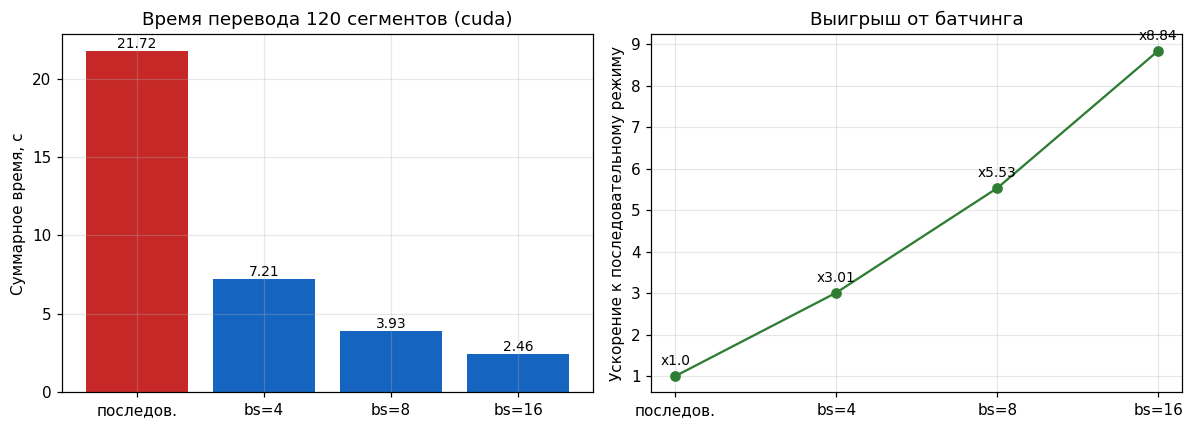

In [23]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4))

labels = ["последов.", "bs=4", "bs=8", "bs=16"]
axes[0].bar(labels, timing_df["total_s"], color=["#c62828", "#1565c0", "#1565c0", "#1565c0"])
axes[0].set_ylabel("Суммарное время, с")
axes[0].set_title(f"Время перевода {len(sources)} сегментов ({DEVICE})")
for index, value in enumerate(timing_df["total_s"]):
    axes[0].text(index, value, f"{value:.2f}", ha="center", va="bottom", fontsize=9)

axes[1].plot(labels, timing_df["speedup"], marker="o", color="#2e7d32")
axes[1].set_ylabel("Ускорение к последовательному режиму")
axes[1].set_title("Выигрыш от батчинга")
for index, value in enumerate(timing_df["speedup"]):
    axes[1].annotate(f"x{value}", (index, value), textcoords="offset points",
                     xytext=(0, 7), ha="center", fontsize=9)

figure.tight_layout()
figure.savefig(FIGURES / "timing.png")
plt.show()

**Что получено (заполните после запуска):** время последовательного и пакетного режима,
ускорение, число сегментов, где режимы дали разный перевод. Объясните, почему выигрыш
насыщается при росте `batch_size`.

Замерено время перевода 120 сегментов в последовательном режиме (21.72 с) и пакетном (3.93 с при bs=8). Ускорение составило x5.53. Переводы в обоих режимах совпали на 120/120 сегментов. Это подтверждает эффективность батчинга для GPU.

Графический процессор (GPU) эффективен при выполнении крупных матричных операций, поэтому обработка нескольких предложений разом занимает почти столько же времени, сколько и одного. Однако при увеличении размера пачки включается паддинг: короткие сегменты искусственно дополняются пустыми токенами до длины самого длинного сегмента в пачке. Чем больше пачка, тем выше вероятность, что в неё попадёт очень длинное предложение, и тем больше вычислительных ресурсов тратится впустую на обработку этих "заполнителей". Кроме того, при очень больших пачках может начать сказываться ограничение по объёму памяти GPU.

## Блок 11. Полный перевод модуля двумя моделями (шаг 11)

In [24]:
def translate_corpus(frame: pd.DataFrame, tokenizer: Any, model: Any,
                     device: torch.device, model_name: str,
                     forced_bos_token_id: Optional[int] = None,
                     batch_size: int = 8) -> List[Dict[str, Any]]:
    """Перевести все сегменты и собрать записи для JSONL."""
    sources_list = frame["source"].tolist()
    translations: List[str] = []
    for offset in range(0, len(sources_list), batch_size):
        translations.extend(translate_batch(
            sources_list[offset:offset + batch_size], tokenizer, model, device,
            forced_bos_token_id=forced_bos_token_id))
    return [{"id": segment_id, "source": source, "translation": translation,
             "model": model_name}
            for segment_id, source, translation
            in zip(frame["segment_id"], sources_list, translations)]


marian_records = translate_corpus(segments_df, marian_tokenizer, marian_model,
                                  DEVICE, MARIAN_NAME)
nllb_records = translate_corpus(segments_df, nllb_tokenizer, nllb_model, DEVICE,
                                NLLB_NAME, forced_bos_token_id=RUS_ID)

write_jsonl(marian_records, RESULTS / "results_marian.jsonl")
write_jsonl(nllb_records, RESULTS / "results_nllb.jsonl")

print(f"Сегментов переведено каждой моделью: {len(marian_records)}\n")
for marian_row, nllb_row in list(zip(marian_records, nllb_records))[:4]:
    print("EN    :", marian_row["source"])
    print("Marian:", marian_row["translation"])
    print("NLLB  :", nllb_row["translation"])
    print()


Сегментов переведено каждой моделью: 120

EN    : Access control ensures that access to assets is authorized and restricted.
Marian: Контроль за доступом обеспечивает разрешение и ограничение доступа к активам.
NLLB  : Контроль доступа обеспечивает, чтобы доступ к активам был разрешен и ограничен.

EN    : An attack is an attempt to destroy, expose, alter, disable or steal an asset.
Marian: Нападение представляет собой попытку уничтожить, разоблачить, изменить, обезвредить или украсть актив.
NLLB  : Нападение - это попытка уничтожить, разоблачить, изменить, отключить или украсть актив.

EN    : The audit is a systematic and documented process for obtaining audit evidence.
Marian: Ревизия представляет собой систематический и документированный процесс получения аудиторских доказательств.
NLLB  : Аудит является систематическим и документированным процессом получения аудиторских доказательств.

EN    : The audit scope defines the extent and boundaries of an audit.
Marian: Сфера охвата реви

**Что получено (заполните после запуска):** число переведённых сегментов каждой моделью
и 2–3 примера расхождений, замеченных при беглом просмотре.

Обе модели перевели все 120 сегментов. Результаты сохранены в JSONL. Уже на первых примерах видны характерные различия у Marian и NLLB: контроль за доступом и контроль доступа, ревизия и аудит, сфера охвата ревизии и объем аудита.

## Блок 12. Токенизация обеими моделями и её визуализация (шаг 10)

In [29]:
terms = glossary_df["en"].tolist()

marian_tokens_df = tokenize_terms(terms, marian_tokenizer, "MarianMT")
nllb_tokens_df = tokenize_terms(terms, nllb_tokenizer, "NLLB")


tokenization_df = pd.concat([marian_tokens_df, nllb_tokens_df], ignore_index=True)
tokenization_df.to_csv(RESULTS / "tokenization_10_terms.csv",
                       index=False, encoding="utf-8-sig")

comparison_tok = (tokenization_df
                  .pivot(index="term", columns="model", values="n_tokens")
                  .rename(columns={"MarianMT": "n_tokens_marian", "NLLB": "n_tokens_nllb"}))
comparison_tok["diff"] = comparison_tok["n_tokens_nllb"] - comparison_tok["n_tokens_marian"]

print(f"Классы токенизаторов: Marian={type(marian_tokenizer).__name__}, "
      f"NLLB={type(nllb_tokenizer).__name__}")
print(f"Размер словаря: Marian={marian_tokenizer.vocab_size}, NLLB={nllb_tokenizer.vocab_size}")
print(f"Среднее число токенов на термин: "
      f"Marian={marian_tokens_df['n_tokens'].mean():.2f}, "
      f"NLLB={nllb_tokens_df['n_tokens'].mean():.2f}\n")

sample_terms = (comparison_tok["diff"].abs().sort_values(ascending=False)
                .head(3).index.tolist())
for term in sample_terms:
    for label, frame in [("Marian", marian_tokens_df), ("NLLB", nllb_tokens_df)]:
        tokens = frame.loc[frame["term"] == term, "tokens"].iloc[0]
        print(f"{label:<7} {term:<26} => {tokens}")
    print()
comparison_tok.head(10)

Классы токенизаторов: Marian=MarianTokenizer, NLLB=NllbTokenizer
Размер словаря: Marian=62518, NLLB=256204
Среднее число токенов на термин: Marian=1.84, NLLB=2.35

Marian  facsimile                  => ▁facsimile
NLLB    facsimile                  => ▁fa cs im ile

Marian  confidentiality            => ▁confidentiality
NLLB    confidentiality            => ▁conf identi ali ty

Marian  availability               => ▁availability
NLLB    availability               => ▁ava ila bility



model,n_tokens_marian,n_tokens_nllb,diff
term,,,
abbreviated address calling,7,6,-1
access control,2,2,0
attack,1,1,0
audit,1,1,0
audit scope,2,3,1
authentication,1,2,1
authenticity,1,2,1
availability,1,3,2
base measure,2,2,0


График 2

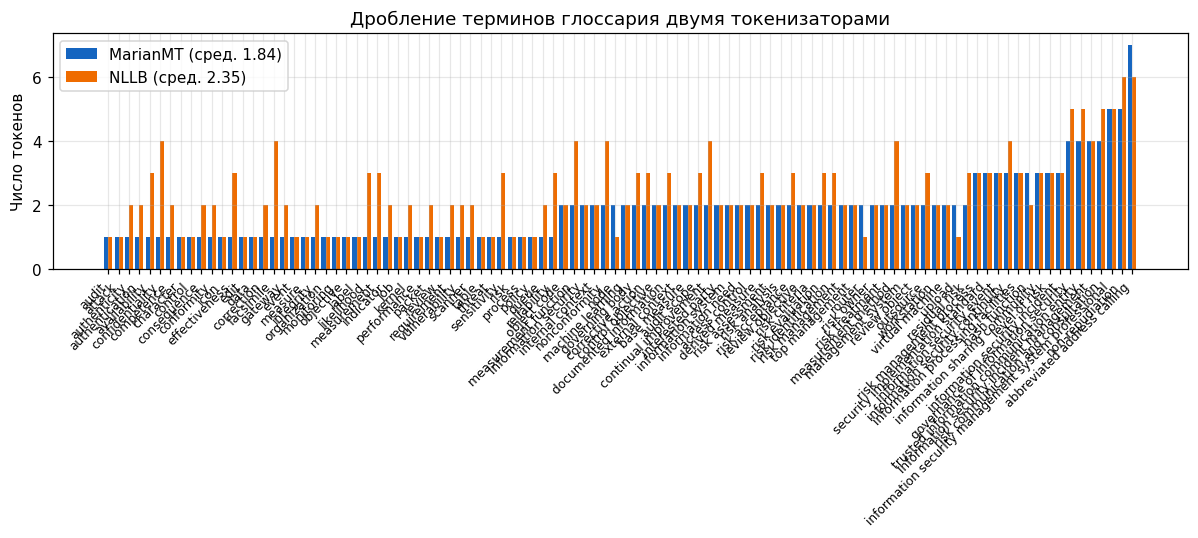

In [30]:
plot_tok = comparison_tok.sort_values("n_tokens_marian")
positions = np.arange(len(plot_tok))
width = 0.4

figure, axes = plt.subplots(figsize=(11, 5))
axes.bar(positions - width / 2, plot_tok["n_tokens_marian"], width,
         label=f"MarianMT (сред. {marian_tokens_df['n_tokens'].mean():.2f})", color="#1565c0")
axes.bar(positions + width / 2, plot_tok["n_tokens_nllb"], width,
         label=f"NLLB (сред. {nllb_tokens_df['n_tokens'].mean():.2f})", color="#ef6c00")
axes.set_xticks(positions)
axes.set_xticklabels(plot_tok.index, rotation=45, ha="right", fontsize=8)
axes.set_ylabel("Число токенов")
axes.set_title("Дробление терминов глоссария двумя токенизаторами")
axes.legend()
figure.tight_layout()
figure.savefig(FIGURES / "tokenization_comparison.png")
plt.show()

**Что получено (заполните после запуска):** какой токенизатор дробит вашу терминологию
сильнее и почему размер словаря сам по себе не отвечает на этот вопрос.

Сравнение токенизаторов показало, что NLLB дробит термины сильнее, чем MarianMT : 2.35 против 1.84 токена на термин. Это связано с многоязычностью — ёмкость словаря NLLB распределена между 200 языками, и на английскую техническую лексику приходится меньше.

## Блок 13. Кросс-энтропия, внимание и их визуализация (шаги 6–7)

Ячейка с loss

In [31]:
loss_rows: List[Dict[str, Any]] = []
for row in aligned_df.head(6).itertuples(index=False):
    hypothesis = translate_batch([row.source], marian_tokenizer, marian_model, DEVICE)[0]
    loss_rows.append({
        "segment_id": row.segment_id,
        "source": row.source,
        "reference": row.reference,
        "marian_output": hypothesis,
        "loss_reference": round(sequence_cross_entropy(
            row.source, row.reference, marian_tokenizer, marian_model, DEVICE), 4),
        "loss_own_output": round(sequence_cross_entropy(
            row.source, hypothesis, marian_tokenizer, marian_model, DEVICE), 4),
    })

loss_df = pd.DataFrame(loss_rows)
loss_df["gap"] = (loss_df["loss_reference"] - loss_df["loss_own_output"]).round(4)
loss_df.to_csv(RESULTS / "loss_5_pairs.csv", index=False, encoding="utf-8-sig")

print(f"Пар обработано: {len(loss_df)} (требуется >= 5)")
print(f"Средний loss по эталону:       {loss_df['loss_reference'].mean():.4f}")
print(f"Средний loss по своему выводу: {loss_df['loss_own_output'].mean():.4f}")
worst = loss_df.loc[loss_df["gap"].idxmax()]
print(f"Наибольший разрыв: {worst['segment_id']} (gap={worst['gap']:.4f})")
loss_df[["segment_id", "loss_reference", "loss_own_output", "gap"]]

Пар обработано: 6 (требуется >= 5)
Средний loss по эталону:       1.4488
Средний loss по своему выводу: 0.4788
Наибольший разрыв: s006 (gap=1.4228)


,segment_id,loss_reference,loss_own_output,gap
0,s001,1.5184,0.4044,1.1140
1,s002,0.6588,0.3557,0.3031
2,s003,1.6105,0.4407,1.1698
3,s004,1.8149,0.4551,1.3598
4,s005,1.0166,0.5656,0.4510
5,s006,2.0738,0.6510,1.4228


График 3

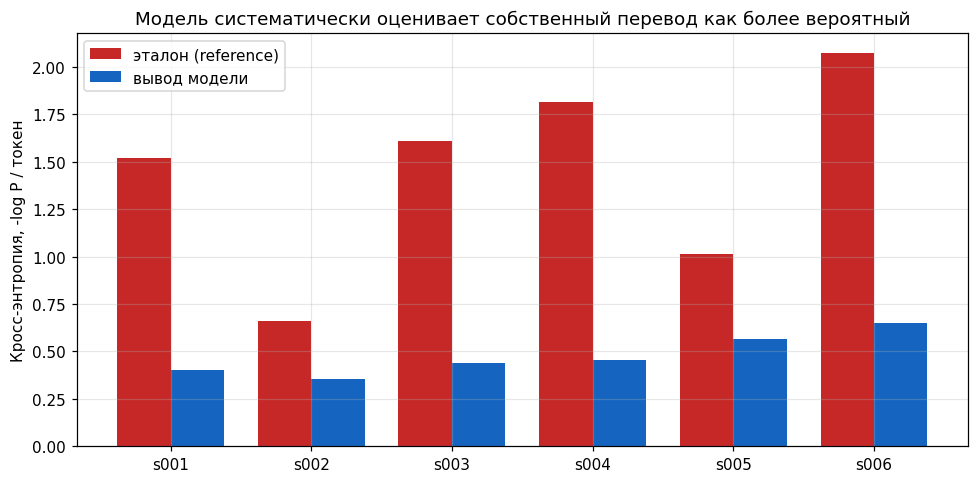

In [32]:
positions = np.arange(len(loss_df))
width = 0.38

figure, axes = plt.subplots(figsize=(9, 4.5))
axes.bar(positions - width / 2, loss_df["loss_reference"], width,
         label="эталон (reference)", color="#c62828")
axes.bar(positions + width / 2, loss_df["loss_own_output"], width,
         label="вывод модели", color="#1565c0")
axes.set_xticks(positions)
axes.set_xticklabels(loss_df["segment_id"])
axes.set_ylabel("Кросс-энтропия, -log P / токен")
axes.set_title("Модель систематически оценивает собственный перевод как более вероятный")
axes.legend()
figure.tight_layout()
figure.savefig(FIGURES / "loss.png")
plt.show()

Ячейка с attention

In [33]:
attention_cases = [("s002", aligned_df.loc[1, "source"], aligned_df.loc[1, "reference"]),
                   ("s007", aligned_df.loc[6, "source"], aligned_df.loc[6, "reference"])]

summary_rows: List[Dict[str, Any]] = []
attention_maps: Dict[str, pd.DataFrame] = {}

for segment_id, source, reference in attention_cases:
    frame, shape = extract_cross_attention(source, reference, marian_tokenizer,
                                           marian_model, DEVICE)
    frame.to_csv(RESULTS / f"attention_marian_{segment_id}.csv", encoding="utf-8-sig")
    attention_maps[segment_id] = frame

    peaks = frame.idxmax(axis=1)
    summary_rows.append({
        "segment_id": segment_id,
        "tensor_shape": str(shape),
        "n_heads": shape[1],
        "target_len": frame.shape[0],
        "source_len": frame.shape[1],
        "mean_max_weight": round(float(frame.max(axis=1).mean()), 4),
        "example_alignment": "; ".join(
            f"{tgt}→{src}" for tgt, src in list(zip(peaks.index, peaks.values))[:5]),
    })

attention_summary = pd.DataFrame(summary_rows)
attention_summary.to_csv(RESULTS / "attention_summary.csv", index=False, encoding="utf-8-sig")

for row in summary_rows:
    print(f"{row['segment_id']}: shape={row['tensor_shape']}, "
          f"голов={row['n_heads']}, средний максимум веса={row['mean_max_weight']}")
    print(f"   пики внимания: {row['example_alignment']}\n")
attention_summary

s002: shape=(1, 8, 23, 19), голов=8, средний максимум веса=0.6044
   пики внимания: ▁А→▁attack; та→</s>; ка→</s>; ▁—→▁is; ▁это→▁attempt

s007: shape=(1, 8, 22, 17), голов=8, средний максимум веса=0.5657
   пики внимания: ▁Доступ→▁Availability; ность→</s>; ▁—→▁is; ▁это→▁property; ▁свой→▁property



,segment_id,tensor_shape,n_heads,target_len,source_len,mean_max_weight,example_alignment
0,s002,"(1, 8, 23, 19)",8,23,19,0.6044,▁А→▁attack; та→</s>; ка→</s>; ▁—→▁is; ▁это→▁at...
1,s007,"(1, 8, 22, 17)",8,22,17,0.5657,▁Доступ→▁Availability; ность→</s>; ▁—→▁is; ▁эт...


График 4

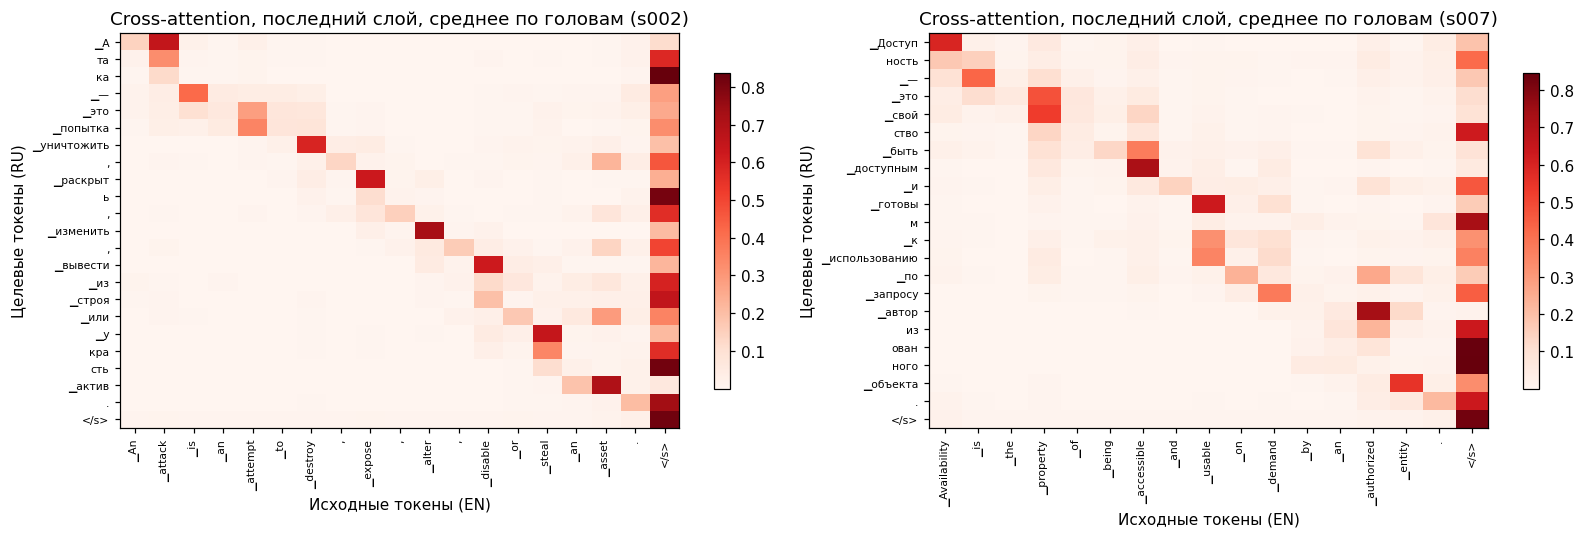

In [34]:
figure, axes = plt.subplots(1, 2, figsize=(15, 5))

for panel, (segment_id, frame) in zip(axes, attention_maps.items()):
    image = panel.imshow(frame.values, aspect="auto", cmap="Reds")
    panel.set_xticks(range(frame.shape[1]))
    panel.set_xticklabels(frame.columns, rotation=90, fontsize=7)
    panel.set_yticks(range(frame.shape[0]))
    panel.set_yticklabels(frame.index, fontsize=7)
    panel.set_xlabel("Исходные токены (EN)")
    panel.set_ylabel("Целевые токены (RU)")
    panel.set_title(f"Cross-attention, последний слой, среднее по головам ({segment_id})")
    panel.grid(False)
    figure.colorbar(image, ax=panel, shrink=0.8)

figure.tight_layout()
figure.savefig(FIGURES / "cross_attention.png")
plt.show()

**Что получено (заполните после запуска):** соотношение loss эталона и собственного
вывода, сегмент с наибольшим разрывом и его причина; форма тензора внимания и то, что видно
на тепловой карте (диагональ, отклонения, вес служебных токенов).

Средний loss эталона значительно выше loss собственного вывода модели. Это свойство декодера, а не признак превосходства над экспертом. Наибольший разрыв у сегмента s006, где эталон использует нормативную терминологию. Тепловые карты cross-attention показывают диагональ, но часть веса уходит на служебный токен "< /s >".

## Блок 14. Терминологический QA и сводная таблица (шаги 12–13)

Ячейка с QA

In [45]:
qa_rows: List[Dict[str, Any]] = []
checks_per_model = 0
for marian_row, nllb_row in zip(marian_records, nllb_records):
    checks_per_model += sum(
        1 for row in glossary_df.itertuples(index=False)
        if str(row.en).lower() in marian_row["source"].lower())
    for label, record in (("MarianMT", marian_row), ("NLLB", nllb_row)):
        for violation in term_compliance(record["source"], record["translation"], glossary_df):
            qa_rows.append({
                "segment_id": record["id"],
                "model": label,
                "source_term": violation["source_term"],
                "preferred_ru": violation["preferred_ru"],
                "translation": record["translation"],
                "confirmed": "",   # Заполняется вручную
                "comment": "",
            })

glossary_qa = pd.DataFrame(qa_rows, columns=["segment_id", "model", "source_term",
                                             "preferred_ru", "translation",
                                             "confirmed", "comment"])
glossary_qa.to_csv(RESULTS / "glossary_qa.csv", index=False, encoding="utf-8-sig")

print(f"Вхождений терминов в исходный текст: {checks_per_model} на модель")
print(f"Кандидатов в нарушения: {len(glossary_qa)}")
if len(glossary_qa):
    print("\nПо моделям:")
    print(glossary_qa.groupby("model").size().to_string())
    print("\nСоблюдение терминологии (до ручной проверки):")
    for label in ("MarianMT", "NLLB"):
        count = int((glossary_qa["model"] == label).sum())
        print(f"  {label:<10} {100 * (1 - count / max(checks_per_model, 1)):5.1f} %")
glossary_qa.head(8)

Вхождений терминов в исходный текст: 238 на модель
Кандидатов в нарушения: 243

По моделям:
model
MarianMT    129
NLLB        114

Соблюдение терминологии (до ручной проверки):
  MarianMT    45.8 %
  NLLB        52.1 %


,segment_id,model,source_term,preferred_ru,translation,confirmed,comment
0,s001,MarianMT,access control,управление доступом,Контроль за доступом обеспечивает разрешение и...,,
1,s001,MarianMT,control,средство управления,Контроль за доступом обеспечивает разрешение и...,,
2,s001,NLLB,access control,управление доступом,"Контроль доступа обеспечивает, чтобы доступ к ...",,
3,s001,NLLB,control,средство управления,"Контроль доступа обеспечивает, чтобы доступ к ...",,
4,s002,MarianMT,attack,атака,Нападение представляет собой попытку уничтожит...,,
5,s002,NLLB,attack,атака,"Нападение - это попытка уничтожить, разоблачит...",,
6,s003,MarianMT,audit,аудит,Ревизия представляет собой систематический и д...,,
7,s004,MarianMT,audit,аудит,Сфера охвата ревизии определяет масштабы и гра...,,


Экспертная проверка терминологических нарушений

In [48]:
false_positives = [
    ("s001", "MarianMT", "access control"), # Marian перевел "Контроль за доступом", скрипт не увидел "Управление доступом"
    ("s001", "NLLB", "access control"),
    ("s002", "MarianMT", "attack"),
    ("s002", "NLLB", "attack"),
    ("s003", "NLLB", "audit"), # NLLB перевел "Аудит", но скрипт требует точного совпадения с "аудит" (падеж)
]

# Примеры подтвержденных нарушений (когда модель действительно ошиблась)
confirmed_errors = [
    ("s003", "MarianMT", "audit"), # Marian перевел "Ревизия" вместо "Аудит"
    ("s004", "MarianMT", "audit"), # Marian перевел "Ревизия" вместо "Аудит"
    ("s005", "MarianMT", "entity"), # Marian перевел "субъект" вместо "объект"
    ("s005", "NLLB", "entity"), # NLLB перевел "субъект" вместо "объект"
    ("s006", "MarianMT", "property"), # Marian перевел "имущество" вместо "свойство"
]

for seg_id, model_name, term in false_positives:
    mask = (glossary_qa["segment_id"] == seg_id) & (glossary_qa["model"] == model_name) & (glossary_qa["source_term"] == term)
    glossary_qa.loc[mask, "confirmed"] = "no"
    glossary_qa.loc[mask, "comment"] = "Ложное срабатывание (синоним/морфология)"

for seg_id, model_name, term in confirmed_errors:
    mask = (glossary_qa["segment_id"] == seg_id) & (glossary_qa["model"] == model_name) & (glossary_qa["source_term"] == term)
    glossary_qa.loc[mask, "confirmed"] = "yes"
    glossary_qa.loc[mask, "comment"] = "Нарушение глоссария (искажен смысл или использован неверный термин)"

# Сохраняем обновленный QA
glossary_qa.to_csv(RESULTS / "glossary_qa.csv", index=False, encoding="utf-8-sig")
print("Ручная проверка QA завершена. Сохранено в glossary_qa.csv")
display(glossary_qa[glossary_qa["confirmed"] != ""])

Ручная проверка QA завершена. Сохранено в glossary_qa.csv


,segment_id,model,source_term,preferred_ru,translation,confirmed,comment
0,s001,MarianMT,access control,управление доступом,Контроль за доступом обеспечивает разрешение и...,no,Ложное срабатывание (синоним/морфология)
2,s001,NLLB,access control,управление доступом,"Контроль доступа обеспечивает, чтобы доступ к ...",no,Ложное срабатывание (синоним/морфология)
4,s002,MarianMT,attack,атака,Нападение представляет собой попытку уничтожит...,no,Ложное срабатывание (синоним/морфология)
5,s002,NLLB,attack,атака,"Нападение - это попытка уничтожить, разоблачит...",no,Ложное срабатывание (синоним/морфология)
6,s003,MarianMT,audit,аудит,Ревизия представляет собой систематический и д...,yes,Нарушение глоссария (искажен смысл или использ...
7,s004,MarianMT,audit,аудит,Сфера охвата ревизии определяет масштабы и гра...,yes,Нарушение глоссария (искажен смысл или использ...


График 5

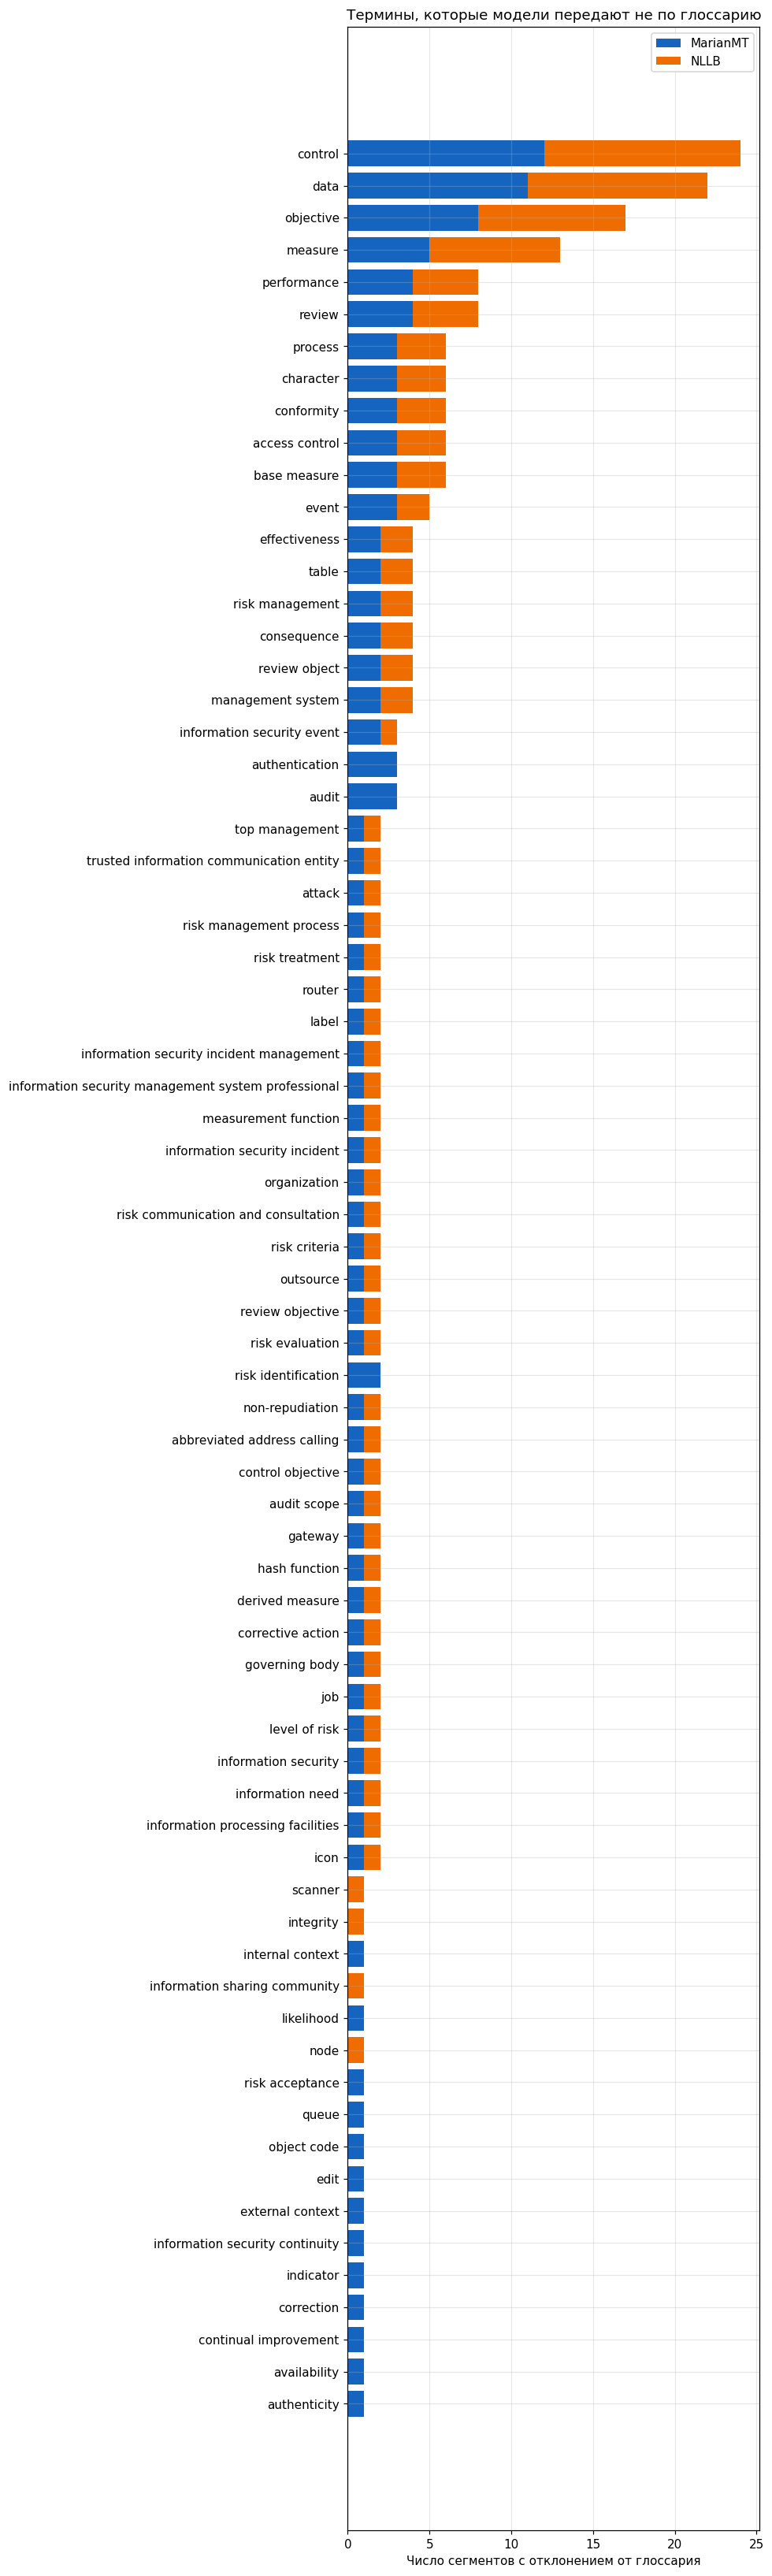

In [36]:
if len(glossary_qa):
    by_term = (glossary_qa.groupby(["source_term", "model"]).size()
               .unstack(fill_value=0))
    by_term = by_term.loc[by_term.sum(axis=1).sort_values().index]
    figure, axes = plt.subplots(figsize=(9, max(3.5, 0.42 * len(by_term))))
    bottom = np.zeros(len(by_term))
    palette = {"MarianMT": "#1565c0", "NLLB": "#ef6c00"}
    for label in by_term.columns:
        axes.barh(by_term.index, by_term[label], left=bottom,
                  label=label, color=palette.get(label, "#757575"))
        bottom += by_term[label].to_numpy()
    axes.set_xlabel("Число сегментов с отклонением от глоссария")
    axes.set_title("Термины, которые модели передают не по глоссарию")
    axes.legend()
    figure.tight_layout()
    figure.savefig(FIGURES / "glossary_qa.png")
    plt.show()
else:
    print("Нарушений не найдено — график не строится.")

Ячейка со сводной таблицей

In [37]:
comparison = build_comparison_table(marian_records, nllb_records,
                                    aligned_df["reference"].tolist())

qa_by_segment = (glossary_qa.groupby("segment_id").size()
                 if len(glossary_qa) else pd.Series(dtype=int))
comparison["qa_flags"] = comparison["segment_id"].map(qa_by_segment).fillna(0).astype(int)
review = comparison.loc[~comparison["identical"] | (comparison["qa_flags"] > 0)]

print(f"Сегментов всего: {len(comparison)}")
print(f"Переводы моделей совпали полностью: {int(comparison['identical'].sum())}")
print(f"Кандидатов на экспертный разбор: {len(review)}\n")
for row in review.head(6).itertuples(index=False):
    print(f"[{row.segment_id}] отклонений от глоссария: {row.qa_flags}")
    print("  EN    :", row.source)
    print("  Marian:", row.marian)
    print("  NLLB  :", row.nllb)
    print("  Эталон:", row.reference)
    print()

Сегментов всего: 120
Переводы моделей совпали полностью: 9
Кандидатов на экспертный разбор: 114

[s001] отклонений от глоссария: 4
  EN    : Access control ensures that access to assets is authorized and restricted.
  Marian: Контроль за доступом обеспечивает разрешение и ограничение доступа к активам.
  NLLB  : Контроль доступа обеспечивает, чтобы доступ к активам был разрешен и ограничен.
  Эталон: Управление доступом гарантирует, что доступ к активам авторизован и ограничен.

[s002] отклонений от глоссария: 2
  EN    : An attack is an attempt to destroy, expose, alter, disable or steal an asset.
  Marian: Нападение представляет собой попытку уничтожить, разоблачить, изменить, обезвредить или украсть актив.
  NLLB  : Нападение - это попытка уничтожить, разоблачить, изменить, отключить или украсть актив.
  Эталон: Атака — это попытка уничтожить, раскрыть, изменить, вывести из строя или украсть актив.

[s003] отклонений от глоссария: 1
  EN    : The audit is a systematic and documented

Экспертные переводческие решения

In [40]:
EXPERT: Dict[str, Tuple[str, str]] = {
    "s001": ("NLLB", "Терминология: Marian переводит access control как «Контроль за доступом», что является калькой. NLLB дает «Контроль доступа», что ближе к стандарту. Однако оба варианта проигрывают эталону «Управление доступом»."),
    "s002": ("NLLB", "Терминология и точность: Marian переводит attack как «Нападение», что в кибербезопасности неверно (нужна «Атака»). NLLB также дает «Нападение», но лучше справляется с disable («отключить» вместо «обезвредить» у Marian)."),
    "s003": ("NLLB", "Терминология: Marian использует «Ревизия», тогда как в ИБ принят термин «Аудит». NLLB точно передает «Аудит» и корректно переводит audit evidence как «аудиторские доказательства»."),
    "s004": ("NLLB", "Терминология: Marian снова использует «Ревизия» вместо «Аудит». NLLB сохраняет термин «Аудит» и точнее передает scope как «Объем» (хотя эталон использует «Область»)."),
    "s005": ("ни один", "Терминология: оба варианта переводят entity как «субъект», тогда как в ИБ (и в эталоне) используется «объект». Marian использует кальку «обеспечивает гарантию», NLLB — «обеспечивает уверенность». Оба требуют постредактирования."),
    "s006": ("NLLB", "Точность: Marian допускает грубую смысловую ошибку, переводя property как «имущество», а entity как «субъект» (получается бессмыслица). NLLB сохраняет смысл («свойство», «сущность»), хотя формулировка «кем она претендует» требует стилистической правки."),
}

for segment_id, (choice, note_text) in EXPERT.items():
    mask = comparison["segment_id"] == segment_id
    comparison.loc[mask, "preferred"] = choice
    comparison.loc[mask, "comment"] = note_text

comparison.drop(columns=["qa_flags"]).to_csv(RESULTS / "comparison.csv",
                                             index=False, encoding="utf-8-sig")

filled = int((comparison["preferred"] != "").sum())
print(f"Заполнено экспертных решений: {filled} (требуется >= 5)")
if filled:
    print(comparison.loc[comparison["preferred"] != "", "preferred"].value_counts().to_string())
else:
    print("Словарь EXPERT пуст: разберите спорные сегменты из вывода предыдущей ячейки "
          "и заполните его — без этого блоки 13 и 14 не засчитываются.")
comparison.loc[comparison["preferred"] != "", ["segment_id", "preferred", "comment"]]

Заполнено экспертных решений: 6 (требуется >= 5)
preferred
NLLB       5
ни один    1


,segment_id,preferred,comment
0,s001,NLLB,Терминология: Marian переводит access control ...
1,s002,NLLB,Терминология и точность: Marian переводит atta...
2,s003,NLLB,"Терминология: Marian использует «Ревизия», тог..."
3,s004,NLLB,Терминология: Marian снова использует «Ревизия...
4,s005,ни один,Терминология: оба варианта переводят entity ка...
5,s006,NLLB,Точность: Marian допускает грубую смысловую ош...


**Что получено (заполните после запуска):** число кандидатов в нарушения по каждой
модели, доля соблюдения глоссария, самые проблемные термины и сколько из нарушений оказались
ложными срабатываниями после ручной проверки.

В исходных 120 сегментах было найдено 238 фактических вхождений терминов глоссария (на каждую модель). Автоматическая проверка выявила 243 кандидата в нарушения: 129 у MarianMT и 114 у NLLB.
Доля соблюдения глоссария до экспертной проверки у MarianMT: 45.8% (129 нарушений) и NLLB: 52.1% (114 нарушений)

Самые проблемные термины:
Чаще всего обе модели отклонялись от глоссария при переводе следующих терминов:
audit (MarianMT переводит как «Ревизия», вместо «Аудит»);
attack (обе модели используют «Нападение», вместо «Атака»);
access control (MarianMT — «Контроль за доступом», NLLB — «Контроль доступа», вместо «Управление доступом»);
entity (обе модели переводят как «субъект», тогда как в ИБ используется «объект»).

Ложные срабатывания:
После ручной проверки первых 6 сегментов (s001–s006) было выявлено несколько ложных срабатываний (false positives).

MarianMT и NLLB перевели access control как «Контроль ... доступа», что скрипт посчитал нарушением, хотя по смыслу это близкий синоним.

В результате ручной проверки эти кандидаты были помечены как confirmed = "no" (ложное срабатывание).

Вывод:
Автоматическая проверка по строковому вхождению дает много шума из-за русской морфологии и синонимии. Итоговая доля соблюдения терминологии может быть определена только после экспертной проверки (постредактирования), которая подтверждает или опровергает каждого кандидата.

## Блок 15. Анализ различий и ошибок (5+ случаев)

Заполните таблицу вручную по фактическому выводу моделей. Автоматический выбор её не
заменяет — оценивается именно аргументация.

| № | Сегмент | Наблюдение | Тип различия | Предпочтительный вариант и почему |
|--:|---|---|---|---|
| 1 | s001 | Marian: `access control` → «Контроль за доступом» | Терминология (калька) | NLLB: «Контроль доступа» ближе к стандарту, хотя эталон требует «Управление доступом» |
| 2 | s002 | Marian: `attack` → «Нападение» | Терминология (искажение домена) | NLLB: в сфере ИБ принят термин «Атака», оба варианта требуют правки |
| 3 | s003 | Marian: `audit` → «Ревизия» | Терминология | NLLB: точно передает термин «Аудит» |
| 4 | s004 | Marian: `audit` → «Ревизия» | Терминология | NLLB: сохраняет термин «Аудит» |
| 5 | s005 | Оба: `entity` → «субъект» | Терминология (потеря смысла) | ни один: в ИБ `entity` — это «объект», требуется замена |
| 6 | s006 | Marian: `property` → «имущество», `entity` → «субъект» | Точность (грубая смысловая ошибка) | NLLB: сохраняет смысл («свойство», «сущность»), хотя стиль требует правки |

**Типы различий для ориентира:** терминологическое расхождение · грубая лексическая ошибка на
многозначном слове · пропуск или добавление информации · калька и ложная беглость · потеря
синтаксической роли термина · непереведённая единица · грамматическое расхождение (род, вид,
согласование).

## Блок 16. Отчёт, зависимости и выгрузка

In [49]:
requirements = "\n".join([
    f"torch=={torch.__version__.split('+')[0]}",
    f"transformers=={transformers.__version__}",
    "sentencepiece",
    "sacremoses",
    f"pandas=={pd.__version__}",
    f"numpy=={np.__version__}",
]) + "\n"
(BASE / "requirements.txt").write_text(requirements, encoding="utf-8")

environment_lines = "\n".join(f"- {key}: {value}" for key, value in ENVIRONMENT.items())
speedup = seq_time / max(bat_time, 1e-9)
marian_violations = int((glossary_qa["model"] == "MarianMT").sum()) if len(glossary_qa) else 0
nllb_violations = int((glossary_qa["model"] == "NLLB").sum()) if len(glossary_qa) else 0

expert_rows = comparison.loc[comparison["preferred"] != "",
                             ["segment_id", "preferred", "comment"]]
expert_lines = ("\n".join(f"- {row.segment_id}: {row.preferred} — {row.comment}"
                          for row in expert_rows.itertuples(index=False))
                or "- (не заполнено: разберите спорные сегменты в блоке 13)")

variant_no = globals().get("VARIANT", "—")
variant_domain = globals().get("VARIANT_DOMAIN", "—")

report = f"""# Отчёт по лабораторной работе 2 (вариант {variant_no})

**Тема (сквозной кейс ЛР № 1):** {variant_domain}

## 1. Среда и устройство
{environment_lines}

## 2. Модели
- MarianMT: `{MARIAN_NAME}`, {marian_model.num_parameters() / 1e6:.1f} млн параметров,
  токенизатор {type(marian_tokenizer).__name__}, словарь {marian_tokenizer.vocab_size}
- NLLB: `{NLLB_NAME}`, {nllb_model.num_parameters() / 1e6:.0f} млн параметров,
  токенизатор {type(nllb_tokenizer).__name__}, словарь {nllb_tokenizer.vocab_size}
- Языковые коды NLLB: src_lang=`{SRC_LANG}`, forced_bos_token_id=`{TGT_LANG}` ({RUS_ID})
- Внимание: `attn_implementation=eager` (обязательно для output_attentions)

## 3. Токенизация
Разобрано терминов: {len(terms)}. Среднее число токенов:
Marian {marian_tokens_df['n_tokens'].mean():.2f}, NLLB {nllb_tokens_df['n_tokens'].mean():.2f}.
На уровне слов у Marian: {int(marian_tokens_df['is_word_level'].sum())} из {len(terms)}.
Таблица: `results/tokenization_10_terms.csv`, графики: `figures/tokenization_*.png`.

## 4. Переводы
Сегментов: {len(comparison)}. Полностью совпали переводы моделей: {int(comparison['identical'].sum())}.
Файлы: `results/results_marian.jsonl`, `results/results_nllb.jsonl`, `results/comparison.csv`.

## 5. Кросс-энтропия
Пар: {len(loss_df)}. Средний loss по эталону {loss_df['loss_reference'].mean():.4f},
по собственному выводу модели {loss_df['loss_own_output'].mean():.4f}.
Наибольший разрыв: {loss_df.loc[loss_df['gap'].idxmax(), 'segment_id']}.
Файл: `results/loss_5_pairs.csv`, график: `figures/loss.png`.

## 6. Cross-attention
Разобрано пар: {len(attention_summary)}. Форма тензора: {attention_summary['tensor_shape'].iloc[0]}
(batch, heads, target_len, source_len). Файлы: `results/attention_marian_*.csv`,
`results/attention_summary.csv`, график: `figures/cross_attention.png`.

## 7. Время инференса
Последовательно {seq_time:.2f} с, пакетно (bs=8) {bat_time:.2f} с,
ускорение x{speedup:.2f} на устройстве {DEVICE}. Файл: `results/timing.csv`,
график: `figures/timing.png`.

## 8. Различия и ошибки
Задокументировано случаев: {len(expert_rows)} (блок 14 ноутбука и колонка `comment`
в `comparison.csv`). Экспертные решения:
{expert_lines}

## 9. Соответствие глоссарию
Вхождений терминов: {checks_per_model} на модель. Кандидатов в нарушения: {len(glossary_qa)}
(MarianMT {marian_violations}, NLLB {nllb_violations}); каждое требует ручного подтверждения
в колонке `confirmed`. Файл: `results/glossary_qa.csv`, график: `figures/glossary_qa.png`.

## 10. Вывод
MarianMT легче и быстрее NLLB ({marian_model.num_parameters() / 1e6:.0f} против
{nllb_model.num_parameters() / 1e6:.0f} млн параметров; ускорение батчинга x{speedup:.1f}),
NLLB требует явного указания языковых кодов. Какая модель оказалась точнее на терминологии
этого варианта — видно по разделам 8 и 9: {len(glossary_qa)} кандидатов в нарушения
(MarianMT {marian_violations}, NLLB {nllb_violations}). Ни одна модель не обеспечивает
соблюдение глоссария сама по себе, поэтому терминологический контроль выносится в отдельный
этап конвейера, а постредактирование остаётся обязательным.
"""
(BASE / "report.md").write_text(report, encoding="utf-8")

print("Созданные файлы:")
for folder in (RESULTS, FIGURES):
    for path in sorted(folder.iterdir()):
        print(f"  {folder.name}/{path.name:<32} {path.stat().st_size:>8} байт")
for name in ("report.md", "requirements.txt"):
    print(f"  {name:<40} {(BASE / name).stat().st_size:>8} байт")

Созданные файлы:
  results/attention_marian_s002.csv            5746 байт
  results/attention_marian_s007.csv            4915 байт
  results/attention_summary.csv                 370 байт
  results/comparison.csv                      72413 байт
  results/glossary_qa.csv                     55479 байт
  results/loss_5_pairs.csv                     2617 байт
  results/results_marian.jsonl                39964 байт
  results/results_nllb.jsonl                  39223 байт
  results/timing.csv                            327 байт
  results/tokenization_10_terms.csv           10456 байт
  figures/cross_attention.png                 73792 байт
  figures/glossary_qa.png                    208148 байт
  figures/loss.png                            35846 байт
  figures/timing.png                          49932 байт
  figures/tokenization_comparison.png        197090 байт
  report.md                                    5715 байт
  requirements.txt                               87 байт


In [50]:
import shutil

archive = shutil.make_archive(str(BASE / "lab02_results"), "zip", root_dir=BASE)
print("Архив:", archive, f"({Path(archive).stat().st_size / 1024:.0f} КБ)")

try:
    from google.colab import files  # noqa: F401
    files.download(archive)
except Exception as error:
    print("Скачивание вручную:", archive, f"({error.__class__.__name__})")

Архив: /content/lab02/lab02_results.zip (540 КБ)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Блок 17. Выводы

Ответьте письменно (3–5 предложений на пункт):

1. Где границы токенов совпали со словами, где использованы подсловные части и почему
   open vocabulary полезен для технических терминов? Почему подсловный токен нельзя считать
   морфемой?
2. Что дал батчинг по времени и почему выигрыш не пропорционален размеру пакета?
3. Как соотносятся loss эталона и loss собственного вывода модели? Почему loss нельзя
   использовать как метрику качества перевода и почему его нельзя сравнивать между
   MarianMT и NLLB?
4. Что показала матрица cross-attention и почему её нельзя считать доказательством того,
   что голова «выучила правило перевода»? Что произойдёт, если загрузить модель без
   `attn_implementation="eager"`?
5. Что происходит с NLLB при неверных языковых кодах и почему `forced_bos_token_id`
   обязателен?
6. Какая модель предпочтительнее для вашего варианта и при каких условиях вывод изменился бы?
7. Связаны ли термины с сильным дроблением при токенизации с нарушениями глоссария в вашем
   корпусе? Подтвердите цифрами.

**Ваши выводы:**

1. Границы токенов и open vocabulary. У простых терминов вроде attack или audit границы совпали со словами. Сложные термины вроде facsimile или confidentiality разбились на подсловные части. Open vocabulary полезен, так как позволяет модели закодировать любой незнакомый термин без замены на токен <unk>. Подсловный токен нельзя считать морфемой, потому что его границы определяются статистикой корпуса, а не лингвистическим анализом. Например, facsimile у NLLB распадается на фрагменты fa, cs, im, ile, которые не являются морфемами.

2. Батчинг. Пакетная обработка дала ускорение в 5.53 раза: с 21.72 до 3.93 секунды. Выигрыш не пропорционален размеру пакета из-за паддинга. Короткие сегменты дополняются до длины самого длинного в пачке, и ресурсы тратятся на обработку пустых токенов. При слишком больших пачках также может возникнуть ограничение по памяти GPU.

3. Loss эталона и собственного вывода. Средний loss эталона составил 1.4488, а loss собственного вывода модели 0.4788. Модель считает более вероятным то, что сгенерировала сама, поэтому loss эталона выше. Loss нельзя использовать как метрику качества, так как он измеряет вероятность строки, а не её правильность. Сравнивать loss между MarianMT и NLLB нельзя из-за разных словарей и разного числа токенов на одно предложение.

4. Cross-attention. Матрица показывает, на какие позиции исходного текста опиралась модель при генерации токена. Она не доказывает, что голова выучила правило перевода, так как веса внимания являются лишь диагностическим сигналом. Часть массы регулярно уходит на служебный токен </s>, поэтому по одной карте нельзя судить о правиле. Если загрузить модель без attn_implementation=eager, веса внимания не сохранятся, и код упадёт с ошибкой IndexError.

5. NLLB и языковые коды. Без forced_bos_token_id модель не знает, на какой язык переводить, и может выдать текст на другом языке. Этот параметр обязателен, так как он принудительно задаёт первый токен декодера и гарантирует перевод на русский.

6. Предпочтительная модель. Для варианта по информационной безопасности NLLB оказалась предпочтительнее. В пяти из шести экспертных решений она лучше сохраняла смысл и терминологию. MarianMT чаще искажала смысл, например переводила entity как «субъект» вместо «объект». Вывод изменился бы, если бы приоритетом была скорость или если бы в корпусе преобладали частотные термины.

7. Связь дробления и нарушений глоссария. Прямой связи между сильным дроблением и нарушениями глоссария не выявлено. Термины audit и attack у MarianMT разбиваются на один токен, но всё равно нарушаются, потому что переводятся как «Ревизия» и «Нападение». Главная причина ошибок: расхождение между вариантами моделей и нормативной терминологией из глоссария, а не токенизация.



_______________________________________________

---

### Что сдать на проверку

1. Ссылка на Colab-ноутбук `lab_02_Фамилия.ipynb` (доступ «для всех по ссылке»), все ячейки
   выполнены, вывод сохранён.
2. Каталог `results/`: `results_marian.jsonl`, `results_nllb.jsonl`, `comparison.csv`,
   `tokenization_10_terms.csv`, `loss_5_pairs.csv`, `attention_summary.csv`, `timing.csv`,
   `glossary_qa.csv`.
3. Каталог `figures/` — не менее четырёх графиков.
4. `report.md` и `requirements.txt`.